# Online Retail: frecuencia y gasto de los clientes
**Cano Vargas Abraham · Tópicos de Big Data**

La pregunta de esta práctica es si los clientes con compras identificadas se pueden separar según la frecuencia con la que compran y el dinero que gastan. Primero preparo las ventas y después construyo una tabla con una fila por cliente.

Se utilizan las técnicas de clase: limpieza con Pandas, `log1p`, comparación de escaladores y K-Means. No se proporciona una etiqueta objetivo.

**Datos:** Chen, D. (2015), [Online Retail, UCI](https://doi.org/10.24432/C5BW33), licencia CC BY 4.0. El CSV incluido se convirtió del Excel oficial, sin filtrar filas. Los importes se expresan en libras esterlinas. Esta implementación se elaboró para cubrir el ejercicio de clase; las interpretaciones numéricas se generan con la ejecución de este notebook.


## 1. Cargar y reconocer las ventas


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import silhouette_score

pd.set_option('display.max_columns', None)
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.grid': True,
                     'grid.alpha': 0.2, 'figure.dpi': 110})
SEMILLA = 42
# Permite ejecutar desde notebooks/, desde U4_1_Clustering/ o desde la raíz del repo.
candidatas = [Path('../data/raw/online_retail.csv'), Path('data/raw/online_retail.csv'),
              Path('U4_1_Clustering/data/raw/online_retail.csv')]
ruta = next((p for p in candidatas if p.exists()), None)
if ruta is None:
    raise FileNotFoundError('Coloca online_retail.csv en U4_1_Clustering/data/raw/.')
carpeta = ruta.parent.parent.parent
salidas = carpeta / 'outputs'
salidas.mkdir(exist_ok=True)
ventas = pd.read_csv(ruta, dtype={'InvoiceNo':'string', 'StockCode':'string'}, encoding='utf-8-sig')
print('Dimensiones originales:', ventas.shape)
display(ventas.head())


Dimensiones originales: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [2]:
display(pd.DataFrame({'Tipo':ventas.dtypes.astype(str), 'Nulos':ventas.isna().sum()}))
print('Duplicados exactos:', ventas.duplicated().sum())
print('Cantidades no positivas:', ventas['Quantity'].le(0).sum())
print('Precios no positivos:', ventas['UnitPrice'].le(0).sum())
print('Cancelaciones:', ventas['InvoiceNo'].str.upper().str.startswith('C', na=False).sum())
display(ventas[['Quantity','UnitPrice']].describe().round(2))


Duplicados exactos: 5268
Cantidades no positivas: 10624
Precios no positivos: 2517
Cancelaciones: 9288


,Tipo,Nulos
InvoiceNo,string,0
StockCode,string,0
Description,str,1454
Quantity,int64,0
InvoiceDate,str,0
UnitPrice,float64,0
CustomerID,float64,135080
Country,str,0


,Quantity,UnitPrice
count,541909.00,541909.00
mean,9.55,4.61
std,218.08,96.76
min,-80995.00,-11062.06
25%,1.00,1.25
50%,3.00,2.08
75%,10.00,4.13
max,80995.00,38970.00


## 2. Limpiar conservando las compras que podemos atribuir a alguien
Elimino duplicados completos, fechas inválidas, clientes sin identificar, cancelaciones y compras con cantidad o precio no positivo. Una descripción faltante no impide calcular el importe, por eso no uso `dropna()` sobre todas las columnas. La tabla de control muestra cuántas filas se pierden en cada paso.


In [3]:
control = [{'Etapa':'Original', 'Filas':len(ventas)}]
compras = ventas.drop_duplicates().copy()
control.append({'Etapa':'Sin duplicados', 'Filas':len(compras)})
compras['InvoiceDate'] = pd.to_datetime(compras['InvoiceDate'], format='mixed', errors='coerce')
compras = compras.dropna(subset=['InvoiceDate']).copy()
control.append({'Etapa':'Fecha válida', 'Filas':len(compras)})
compras = compras.dropna(subset=['CustomerID']).copy()
control.append({'Etapa':'Cliente identificado', 'Filas':len(compras)})
es_compra = (compras['Quantity'].gt(0) & compras['UnitPrice'].gt(0)
             & ~compras['InvoiceNo'].str.upper().str.startswith('C', na=False))
compras = compras.loc[es_compra].copy()
compras['CustomerID'] = compras['CustomerID'].astype('int64')
control.append({'Etapa':'Compra positiva no cancelada', 'Filas':len(compras)})
control = pd.DataFrame(control)
control['Retiradas_en_paso'] = control['Filas'].shift().sub(control['Filas']).fillna(0).astype(int)
display(control)
assert not compras.empty
assert compras[['CustomerID','InvoiceDate','Quantity','UnitPrice']].notna().all().all()
assert compras['Quantity'].gt(0).all() and compras['UnitPrice'].gt(0).all()


,Etapa,Filas,Retiradas_en_paso
0,Original,541909,0
1,Sin duplicados,536641,5268
2,Fecha válida,536641,0
3,Cliente identificado,401604,135037
4,Compra positiva no cancelada,392692,8912


## 3. Cambiar de líneas de factura a clientes
El importe de una línea es cantidad por precio. La frecuencia es el número de **facturas distintas**, no el número de renglones. Sumo los importes para obtener el gasto acumulado durante el periodo del archivo. `CustomerID` identifica cada fila y queda fuera de las distancias.


In [4]:
compras['importe'] = compras['Quantity'] * compras['UnitPrice']
clientes = compras.groupby('CustomerID').agg(
    numero_facturas=('InvoiceNo','nunique'), gasto_total=('importe','sum'))
columnas = ['numero_facturas','gasto_total']
X = clientes[columnas].copy()
display(clientes.head())
display(X.describe().round(2))
print('Clientes analizados:', len(clientes))
print('Periodo:', compras['InvoiceDate'].min(), 'a', compras['InvoiceDate'].max())
assert clientes.index.is_unique and (X > 0).all().all()


Clientes analizados: 4338
Periodo: 2010-12-01 08:26:00 a 2011-12-09 12:50:00


,numero_facturas,gasto_total
CustomerID,,
12346,1,77183.60
12347,7,4310.00
12348,4,1797.24
12349,1,1757.55
12350,1,334.40


,numero_facturas,gasto_total
count,4338.00,4338.00
mean,4.27,2048.69
std,7.70,8985.23
min,1.00,3.75
25%,1.00,306.48
50%,2.00,668.57
75%,5.00,1660.60
max,209.00,280206.02


## 4. Explorar la distribución y reducir la asimetría
Unos pocos clientes pueden concentrar compras grandes. `log1p` comprime esas diferencias; no elimina clientes ni garantiza una distribución normal. También comparo la correlación antes y después: describe asociación, no causalidad.


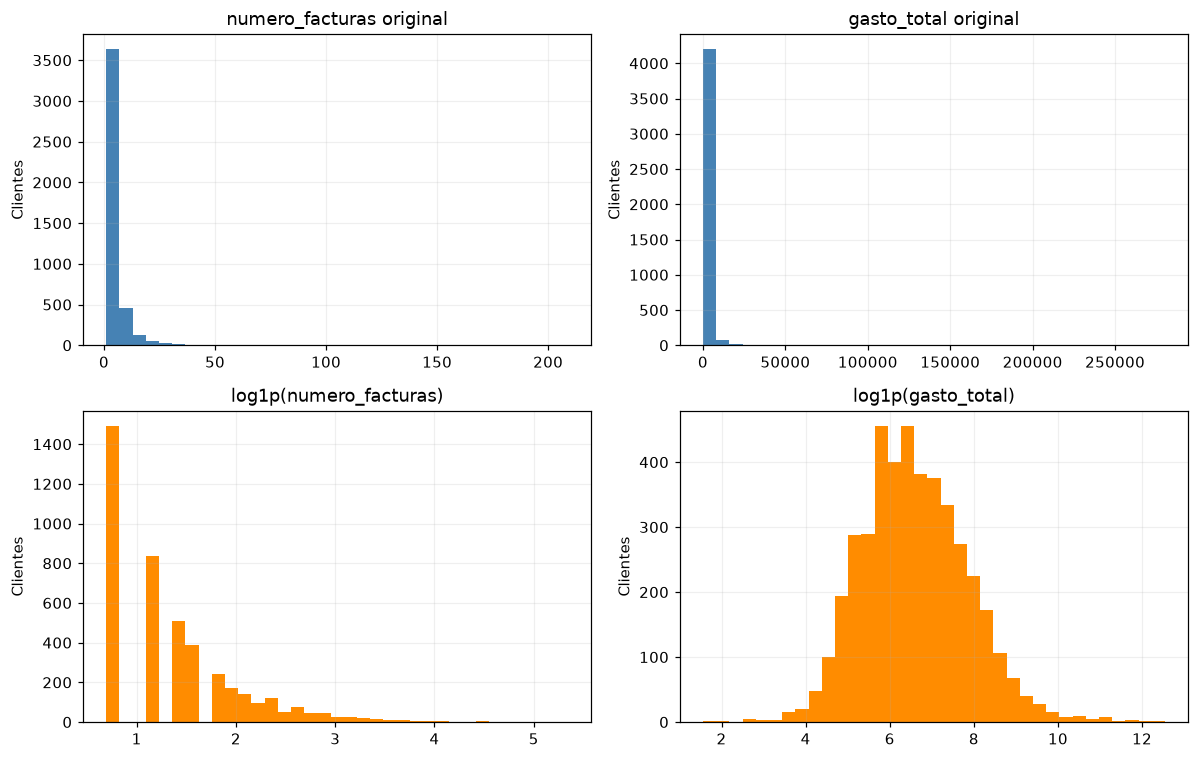

,Original,Con log1p
numero_facturas,1.00000,1.000000
gasto_total,0.55278,0.808119


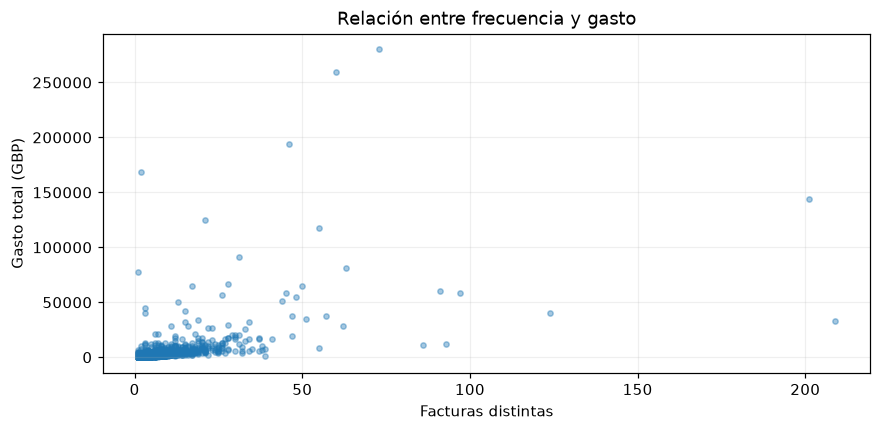

In [5]:
X_log = np.log1p(X)
fig, ejes = plt.subplots(2, 2, figsize=(11, 7))
for j, variable in enumerate(columnas):
    ejes[0,j].hist(X[variable], bins=35, color='steelblue')
    ejes[0,j].set_title(variable + ' original')
    ejes[1,j].hist(X_log[variable], bins=35, color='darkorange')
    ejes[1,j].set_title('log1p(' + variable + ')')
    for i in range(2): ejes[i,j].set_ylabel('Clientes')
plt.tight_layout(); plt.show()
display(pd.DataFrame({'Original':X.corr().iloc[:,0], 'Con log1p':X_log.corr().iloc[:,0]}))
plt.scatter(X['numero_facturas'], X['gasto_total'], s=12, alpha=.4)
plt.xlabel('Facturas distintas'); plt.ylabel('Gasto total (GBP)')
plt.title('Relación entre frecuencia y gasto'); plt.show()


## 5. Comparar Min-Max y StandardScaler
Min-Max sitúa los valores ajustados entre 0 y 1. StandardScaler centra cada columna en cero y la divide por su desviación estándar. Son dos alternativas aplicadas a la misma tabla logarítmica; no las aplico una después de otra. Para K-Means continúo con StandardScaler.


In [6]:
normalizador = MinMaxScaler()
escalador = StandardScaler()
X_minmax = pd.DataFrame(normalizador.fit_transform(X_log), columns=columnas, index=X.index)
X_std = pd.DataFrame(escalador.fit_transform(X_log), columns=columnas, index=X.index)
display(X_minmax.agg(['min','max']).round(4))
display(pd.DataFrame({'Media':X_std.mean(), 'Desviación':X_std.std(ddof=0)}).round(4))
assert np.allclose(X_std.mean(), 0, atol=1e-9)
assert np.allclose(X_std.std(ddof=0), 1)


,numero_facturas,gasto_total
min,0.0,0.0
max,1.0,1.0


,Media,Desviación
numero_facturas,-0.0,1.0
gasto_total,-0.0,1.0


## 6. Comparar el número de grupos
Pruebo de 2 a 8 grupos usando las mismas entradas. La inercia disminuye al añadir grupos; por eso no basta elegir su mínimo. La silueta compara la cercanía al propio grupo frente a otros. Aquí se calcula sobre todos los clientes.


,k,Inercia,Silueta
0,2,3483.3230,0.5287
1,3,2174.6687,0.4588
2,4,1608.1005,0.4233
3,5,1313.2871,0.3828
4,6,1117.4253,0.3724
5,7,974.3252,0.3719
6,8,846.6887,0.3981


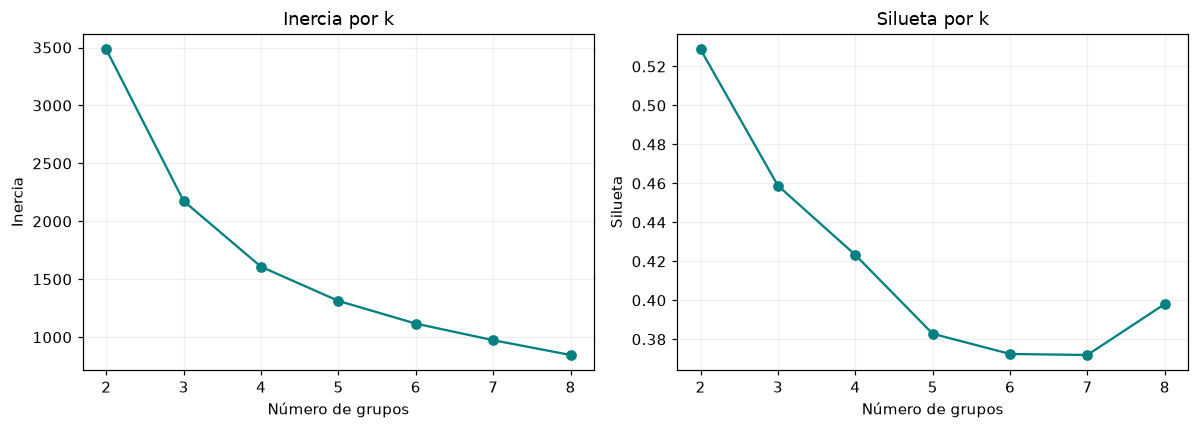

In [7]:
mediciones = []
for k in range(2, 9):
    candidato = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA)
    etiquetas = candidato.fit_predict(X_std)
    mediciones.append({'k':k, 'Inercia':candidato.inertia_,
                       'Silueta':silhouette_score(X_std, etiquetas)})
metricas = pd.DataFrame(mediciones)
display(metricas.round(4))
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
for eje, metrica in zip(ejes, ['Inercia','Silueta']):
    eje.plot(metricas['k'], metricas[metrica], 'o-', color='teal')
    eje.set(xlabel='Número de grupos', ylabel=metrica, title=metrica + ' por k')
    eje.set_xticks(metricas['k'])
plt.tight_layout(); plt.show()


## 7. Elegir una solución y observar sus perfiles
Como criterio reproducible elijo la mayor silueta entre los candidatos. La gráfica del codo y las medianas ayudan a decidir si esa separación tiene sentido. Esta regla no demuestra que exista un único número verdadero de tipos de cliente.


k seleccionado: 2


,clientes,facturas_mediana,gasto_mediano_GBP,facturas_media,gasto_medio_GBP,Porcentaje
Grupo,,,,,,
0,2799,1.0,378.20,1.70,478.76,64.52
1,1539,6.0,2263.12,8.95,4903.93,35.48


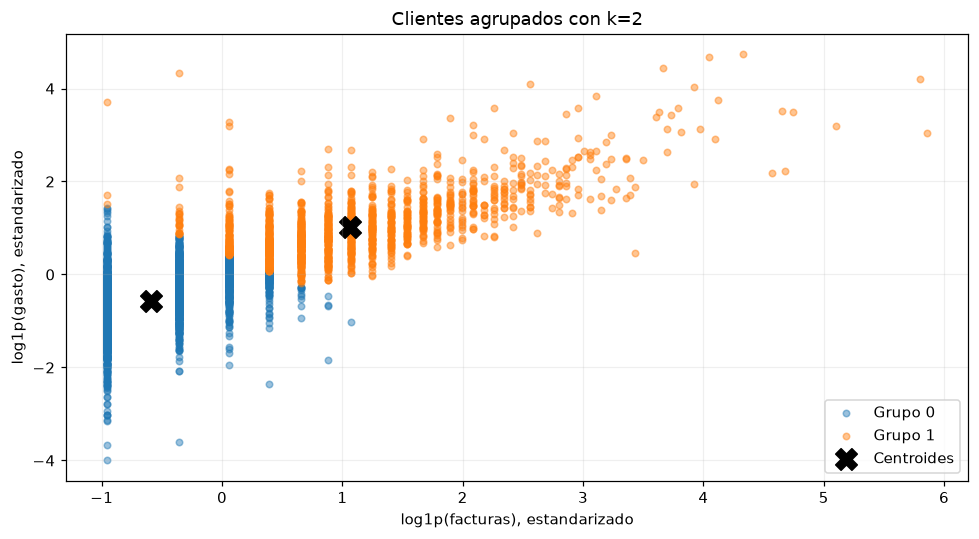

In [8]:
k_final = int(metricas.loc[metricas['Silueta'].idxmax(), 'k'])
modelo = KMeans(n_clusters=k_final, n_init=10, random_state=SEMILLA)
clientes['Grupo'] = modelo.fit_predict(X_std)
resumen = clientes.groupby('Grupo').agg(
    clientes=('numero_facturas','size'), facturas_mediana=('numero_facturas','median'),
    gasto_mediano_GBP=('gasto_total','median'), facturas_media=('numero_facturas','mean'),
    gasto_medio_GBP=('gasto_total','mean'))
resumen['Porcentaje'] = resumen['clientes'] / len(clientes) * 100
print('k seleccionado:', k_final)
display(resumen.round(2))
assert resumen['clientes'].sum() == len(clientes)
fig, eje = plt.subplots(figsize=(9, 5))
for grupo in resumen.index:
    seleccion = clientes['Grupo'].eq(grupo)
    eje.scatter(X_std.loc[seleccion,columnas[0]], X_std.loc[seleccion,columnas[1]],
                s=18, alpha=.45, label=f'Grupo {grupo}')
centros = modelo.cluster_centers_
eje.scatter(centros[:,0], centros[:,1], marker='X', s=200, color='black', label='Centroides')
eje.set(xlabel='log1p(facturas), estandarizado', ylabel='log1p(gasto), estandarizado',
        title=f'Clientes agrupados con k={k_final}')
eje.legend(); plt.tight_layout()
fig.savefig(salidas/'clientes_clusters.png', bbox_inches='tight'); plt.show()


## 8. Interpretación de esta ejecución


In [9]:
mejor = metricas.loc[metricas['k'].eq(k_final)].iloc[0]
texto = [f"Se analizaron **{len(clientes):,} clientes** a partir de **{len(compras):,} líneas válidas**. "
         f"El criterio de mayor silueta eligió **k={k_final}**, con **{mejor['Silueta']:.3f}**."]
for grupo, fila in resumen.iterrows():
    texto.append(f"- Grupo {grupo}: {int(fila['clientes']):,} clientes ({fila['Porcentaje']:.1f}%). "
                 f"Su mediana es {fila['facturas_mediana']:g} facturas y £{fila['gasto_mediano_GBP']:,.2f} de gasto.")
texto.append('Los grupos describen diferencias de frecuencia y monto durante este periodo. '
             'No permiten afirmar lealtad o abandono porque no incluí recencia; tampoco rentabilidad, '
             'porque el archivo no proporciona los costos. Las etiquetas de grupo son nombres, no calificaciones.')
display(Markdown('\n\n'.join(texto)))
metricas.to_csv(salidas/'clientes_metricas.csv', index=False)
resumen.to_csv(salidas/'clientes_perfiles.csv')


Se analizaron **4,338 clientes** a partir de **392,692 líneas válidas**. El criterio de mayor silueta eligió **k=2**, con **0.529**.

- Grupo 0: 2,799 clientes (64.5%). Su mediana es 1 facturas y £378.20 de gasto.

- Grupo 1: 1,539 clientes (35.5%). Su mediana es 6 facturas y £2,263.12 de gasto.

Los grupos describen diferencias de frecuencia y monto durante este periodo. No permiten afirmar lealtad o abandono porque no incluí recencia; tampoco rentabilidad, porque el archivo no proporciona los costos. Las etiquetas de grupo son nombres, no calificaciones.

## 9. Respuestas de análisis
- **¿Por qué no entra CustomerID?** Su valor es un código: dos números cercanos no significan clientes parecidos.
- **¿Por qué resumir primero?** Si agrupara directamente los renglones, estudiaría compras individuales y un cliente podría aparecer en varios grupos.
- **¿Qué cambia al escalar?** Las dos variables pueden contribuir a la distancia sin que el gasto domine solo por su magnitud.
- **¿Qué información se pierde?** Fechas, productos, devoluciones y diferencias entre compras del mismo cliente. Dos personas pueden tener el mismo total con comportamientos distintos.
- **¿Qué se puede concluir?** Se pueden describir perfiles de frecuencia y gasto dentro de las compras seleccionadas. No se demuestra una causa ni un comportamiento futuro.


### Lectura de las métricas

Al pasar de 2 a 3 grupos la inercia baja de 3,483.32 a 2,174.67, pero la silueta desciende de 0.529 a 0.459. Para este ejercicio conservo dos grupos porque separan perfiles de menor y mayor frecuencia y gasto con la mayor silueta de los candidatos. La reducción de inercia por sí sola no obliga a elegir tres. Los histogramas muestran que el logaritmo hace más visible la distribución central, aunque siguen existiendo diferencias entre clientes.
